CS3390 Foundations of Machine Learning Assignment 2  

Name: Pathri Vidya Praveen  
Roll Number: CS24BTECH11047  

Note: The entire assignment 2 has been individually done by myself.

Question 1 : Random Forest  

Dataset: Spam (4601 emails, 57 features, 39.4% spam). 70/30 stratified train/test split (`random_state=42`).  

## Part (a): Random Forest from Scratch vs Scikit-learn
Custom implementation (no built-in tree functions): bootstrap sampling, random subset of m = ⌊√p⌋ = 7 features per split, Gini impurity, fully grown trees, class probabilities averaged over 100 trees. Compared with `sklearn.ensemble.RandomForestClassifier` under identical settings.

In [1]:
# part (a)
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("https://sites.stat.washington.edu/courses/stat527/s14/homework/hw5/spam.data",sep=r"\s+",header=None)
X,y = df.iloc[:,:-1].to_numpy(float),df.iloc[:,-1].to_numpy(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


class DecisionTree:
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features="sqrt", n_classes=2, rng=None):
        self.max_depth, self.min_samples_split, self.min_samples_leaf = max_depth, min_samples_split, min_samples_leaf
        self.max_features, self.C = max_features, n_classes
        self.rng = rng if rng is not None else np.random.default_rng()

    def fit(self, X, y):
        d = X.shape[1]
        mf = self.max_features
        self.k = max(1, int(np.sqrt(d))) if mf == "sqrt" else max(1, int(np.log2(d))) if mf == "log2" else d if mf is None else int(mf)
        self.feat, self.thr, self.left, self.right, self.value = [], [], [], [], []
        self._grow(X, y, 0)
        self.feat, self.thr, self.left, self.right, self.value = map(np.array, (self.feat, self.thr, self.left, self.right, self.value))
        return self

    def _eval(self, X, y, F):
        n, L = len(y), self.min_samples_leaf
        XF = X[:, F]
        o = np.argsort(XF, axis=0)
        xs = np.take_along_axis(XF, o, 0)
        yo = y[o]
        nl = np.arange(1, n)[:, None]
        tot = np.bincount(y, minlength=self.C)
        sq = np.zeros((n - 1, len(F)))
        for c in range(self.C):
            cl = np.cumsum(yo == c, 0)[:-1]
            sq += cl ** 2 / nl + (tot[c] - cl) ** 2 / (n - nl)
        w = n - sq
        valid = xs[1:] > xs[:-1]
        valid[: L - 1], valid[n - L:] = False, False
        w[~valid] = np.inf
        return w, xs

    def _best_split(self, X, y):
        nonconst = np.flatnonzero(X.max(0) > X.min(0))
        if len(nonconst) == 0:
            return None, None
        F = self.rng.permutation(nonconst)[: self.k]
        w, xs = self._eval(X, y, F)
        i, j = np.unravel_index(np.argmin(w), w.shape)
        if not np.isfinite(w[i, j]):
            return None, None
        return F[j], (xs[i, j] + xs[i + 1, j]) / 2

    def _grow(self, X, y, depth):
        idx = len(self.feat)
        cnt = np.bincount(y, minlength=self.C)
        self.feat.append(-1); self.thr.append(0.0); self.left.append(-1); self.right.append(-1)
        self.value.append(cnt / cnt.sum())
        if (cnt > 0).sum() == 1 or len(y) < max(self.min_samples_split, 2 * self.min_samples_leaf) or \
                (self.max_depth is not None and depth >= self.max_depth):
            return idx
        f, t = self._best_split(X, y)
        if f is None:
            return idx
        m = X[:, f] <= t
        self.feat[idx], self.thr[idx] = f, t
        self.left[idx] = self._grow(X[m], y[m], depth + 1)
        self.right[idx] = self._grow(X[~m], y[~m], depth + 1)
        return idx

    def predict_proba(self, X):
        node = np.zeros(len(X), dtype=int)
        a = np.arange(len(X))
        while len(a):
            nd = node[a]
            node[a] = np.where(X[a, self.feat[nd]] <= self.thr[nd], self.left[nd], self.right[nd])
            a = a[self.feat[node[a]] >= 0]
        return self.value[node]


class RandomForest:
    def __init__(self, n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features="sqrt", random_state=None):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_split, self.min_samples_leaf, self.max_features = min_samples_split, min_samples_leaf, max_features
        self.rng = np.random.default_rng(random_state)

    def fit(self, X, y):
        self.classes_, y = np.unique(y, return_inverse=True)
        n = len(y)
        self.trees = []
        for _ in range(self.n_estimators):
            b = self.rng.integers(0, n, n)
            t = DecisionTree(self.max_depth, self.min_samples_split, self.min_samples_leaf, self.max_features, len(self.classes_), self.rng)
            self.trees.append(t.fit(X[b], y[b]))
        return self

    def predict_proba(self, X):
        return np.mean([t.predict_proba(X) for t in self.trees], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


res = {}
for name, model in [("Custom RF", RandomForest(n_estimators=100, random_state=42)),("Sklearn RF", RandomForestClassifier(n_estimators=100, random_state=42))]:
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); t1 = time.perf_counter()
    pred = model.predict(X_te); t2 = time.perf_counter()
    res[name] = {"Accuracy": accuracy_score(y_te, pred), "Train time (s)": t1 - t0, "Predict time (s)": t2 - t1}

print(f"Train: {X_tr.shape}, Test: {X_te.shape}")
print(pd.DataFrame(res).T.round(4))

Train: (3220, 57), Test: (1381, 57)
            Accuracy  Train time (s)  Predict time (s)
Custom RF     0.9544          9.8241            0.2663
Sklearn RF    0.9558          2.0291            0.0340


**Observations**
- Accuracy: custom 0.9544 vs sklearn 0.9558. The difference is 2 of 1381 test emails, within seed-to-seed variation for identical settings.
- Training time: custom ≈ 9.8 s vs sklearn ≈ 2.0 s (~5× slower). Sklearn's tree builder is compiled (Cython); ours is Python + NumPy, vectorised across candidate features at each node.

## Part (b): Sensitivity to m (features considered per split)
Forests of 100 trees trained for m ∈ {1, …, 57}. m = 57 = p corresponds to bagging.

    Test error  OOB error  Train time (s)
m                                        
1       0.0442     0.0469         18.1473
2       0.0449     0.0503         10.3819
3       0.0478     0.0491          8.2476
4       0.0442     0.0500          9.0209
5       0.0463     0.0488          9.3362
7       0.0456     0.0494          8.3098
10      0.0485     0.0531         11.3511
15      0.0536     0.0506         18.2174
20      0.0558     0.0534         17.6715
30      0.0579     0.0559         18.9865
40      0.0579     0.0578         25.3778
57      0.0558     0.0575         34.6221

Best m (OOB): 1   Best m (test): 1   sqrt(p) = 7


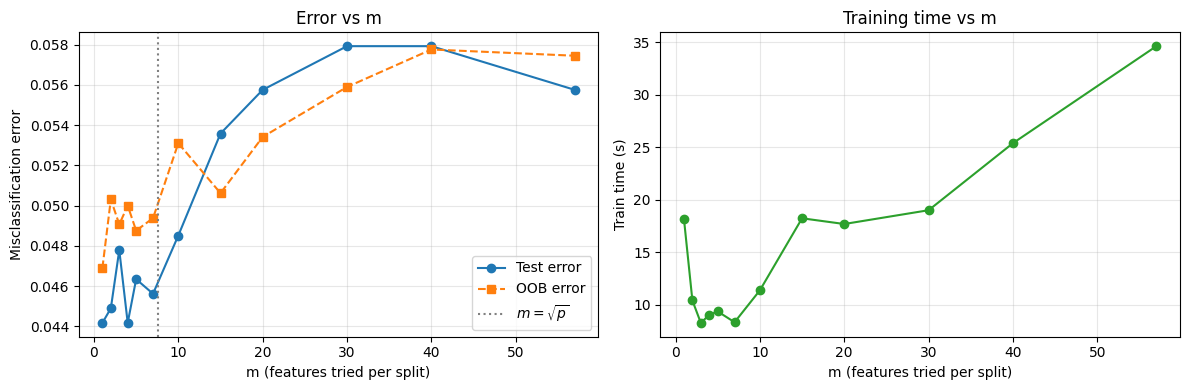

In [2]:
# part (b)

import matplotlib.pyplot as plt


class RandomForestOOB(RandomForest):
    def fit(self, X, y):
        self.classes_, y = np.unique(y, return_inverse=True)
        n, C = len(y), len(self.classes_)
        self.trees, oob = [], np.zeros((n, C))
        for _ in range(self.n_estimators):
            b = self.rng.integers(0, n, n)
            t = DecisionTree(self.max_depth, self.min_samples_split, self.min_samples_leaf, self.max_features, C, self.rng).fit(X[b], y[b])
            self.trees.append(t)
            o = np.setdiff1d(np.arange(n), b)
            oob[o] += t.predict_proba(X[o])
        seen = oob.sum(1) > 0
        self.oob_error_ = np.mean(oob[seen].argmax(1) != y[seen])
        return self


ms = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 57]
rows = []
for m in ms:
    rf = RandomForestOOB(n_estimators=100, max_features=m, random_state=42)
    t0 = time.perf_counter(); rf.fit(X_tr, y_tr); t1 = time.perf_counter()
    rows.append({"m": m, "Test error": 1 - accuracy_score(y_te, rf.predict(X_te)), "OOB error": rf.oob_error_, "Train time (s)": t1 - t0})

res2 = pd.DataFrame(rows).set_index("m")
print(res2.round(4))
print(f"\nBest m (OOB): {res2['OOB error'].idxmin()}   Best m (test): {res2['Test error'].idxmin()}   sqrt(p) = {int(np.sqrt(X.shape[1]))}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ms, res2["Test error"], "o-", label="Test error")
ax[0].plot(ms, res2["OOB error"], "s--", label="OOB error")
ax[0].axvline(np.sqrt(X.shape[1]), color="gray", ls=":", label=r"$m=\sqrt{p}$")
ax[0].set(xlabel="m (features tried per split)", ylabel="Misclassification error", title="Error vs m")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ms, res2["Train time (s)"], "o-", color="tab:green")
ax[1].set(xlabel="m (features tried per split)", ylabel="Train time (s)", title="Training time vs m")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observations**
- Error is lowest and roughly flat for m ≈ 1–7 (~4.5–5%) and rises to ~5.6–5.8% for m ≥ 30.
- Small m decorrelates the trees, so averaging removes more variance. Large m lets every tree pick the same dominant features (e.g. `char_freq_!`, `char_freq_$`), producing correlated trees. At m = p the forest reduces to bagging.
- The default m = √p ≈ 7 lies in the low-error region.
- - Training time grows with m for m ≥ 7 (more features sorted and scored per split); m = 57 is ~4× slower than m = 7. Very small m (1–2) is also slower, because weak random splits produce deeper trees.
- Fluctuations of ~0.3% between neighbouring m (4–5 test emails) are noise; only the overall trend is meaningful.

## Part (c): OOB Error vs Test Error over m
For each tree, the samples left out of its bootstrap sample (~37%) are its out-of-bag (OOB) set. Each training point is predicted only by trees for which it is OOB. Both errors are also tracked as trees are added.

    OOB error  Test error
m                        
1      0.0469      0.0442
2      0.0503      0.0449
3      0.0491      0.0478
4      0.0500      0.0442
5      0.0488      0.0463
6      0.0506      0.0492
7      0.0494      0.0456
8      0.0491      0.0492
10     0.0531      0.0485
12     0.0531      0.0521
15     0.0506      0.0536
20     0.0534      0.0558
25     0.0543      0.0536
30     0.0559      0.0579
40     0.0578      0.0579
50     0.0571      0.0601
57     0.0575      0.0558

Best m (OOB): 1   Best m (test): 1   Corr(OOB, test) = 0.882


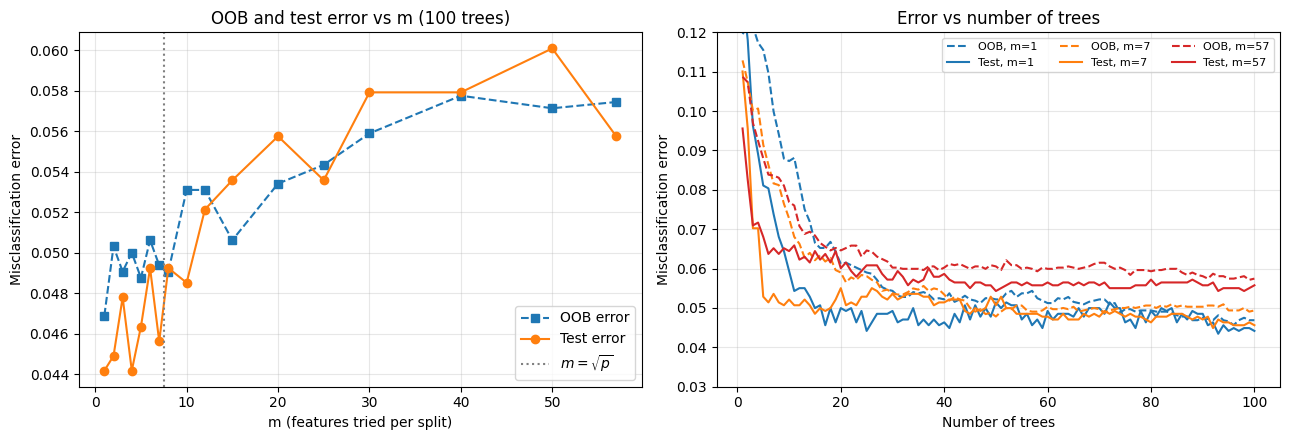

In [3]:
# part (c)

def oob_test_curves(m, n_trees=100, seed=42):
    rng = np.random.default_rng(seed)
    n, C = len(y_tr), 2
    oob_p, te_p = np.zeros((n, C)), np.zeros((len(y_te), C))
    oob_err, te_err = [], []
    for _ in range(n_trees):
        b = rng.integers(0, n, n)
        t = DecisionTree(max_features=m, n_classes=C, rng=rng).fit(X_tr[b], y_tr[b])
        o = np.setdiff1d(np.arange(n), b)
        oob_p[o] += t.predict_proba(X_tr[o])
        te_p += t.predict_proba(X_te)
        seen = oob_p.sum(1) > 0
        oob_err.append(np.mean(oob_p[seen].argmax(1) != y_tr[seen]))
        te_err.append(np.mean(te_p.argmax(1) != y_te))
    return np.array(oob_err), np.array(te_err)


ms3 = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, 25, 30, 40, 50, 57]
curves = {m: oob_test_curves(m) for m in ms3}
res3 = pd.DataFrame({"OOB error": [curves[m][0][-1] for m in ms3],
                     "Test error": [curves[m][1][-1] for m in ms3]}, index=pd.Index(ms3, name="m"))
print(res3.round(4))
print(f"\nBest m (OOB): {res3['OOB error'].idxmin()}   Best m (test): {res3['Test error'].idxmin()}   "
      f"Corr(OOB, test) = {res3['OOB error'].corr(res3['Test error']):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ms3, res3["OOB error"], "s--", label="OOB error")
ax[0].plot(ms3, res3["Test error"], "o-", label="Test error")
ax[0].axvline(np.sqrt(X.shape[1]), color="gray", ls=":", label=r"$m=\sqrt{p}$")
ax[0].set(xlabel="m (features tried per split)", ylabel="Misclassification error", title="OOB and test error vs m (100 trees)")
ax[0].legend(); ax[0].grid(alpha=0.3)
for m, c in zip([1, 7, 57], ["tab:blue", "tab:orange", "tab:red"]):
    k = np.arange(1, len(curves[m][0]) + 1)
    ax[1].plot(k, curves[m][0], "--", color=c, label=f"OOB, m={m}")
    ax[1].plot(k, curves[m][1], "-", color=c, label=f"Test, m={m}")
ax[1].set(xlabel="Number of trees", ylabel="Misclassification error", title="Error vs number of trees", ylim=(0.03, 0.12))
ax[1].legend(ncol=3, fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observations**
- OOB error closely tracks test error across m (correlation ≈ 0.88); both are lowest at small m and highest near m = p.
- OOB error therefore gives a reliable estimate of generalisation error without a separate validation set, and can be used to select m.
- OOB error is slightly higher at small m, since each OOB prediction averages only ~37 trees rather than all 100.
- Both errors level off after ~40–60 trees, so 100 trees is enough; bagging (m = 57) levels off at the highest error.